# 08 — Model Interpretation

## Objective

This notebook interprets the final Gradient Boosting churn model after model selection and final evaluation have been completed.

The goal is to identify which customer characteristics contribute most strongly to predictive performance and compare these results with patterns previously observed during exploratory data analysis.

Interpretation is performed post-hoc and will not be used to modify the finalized model, hyperparameters or classification threshold.

Feature importance represents predictive relevance and should not be interpreted as evidence of causality.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance

In [3]:
PROJECT_ROOT = Path("..")

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "WA_FnUseC_TelcoCustomerChurn.csv"
)

df = pd.read_csv(DATA_PATH)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape

((5634, 19), (1409, 19))

In [4]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    column
    for column in X_train.columns
    if column not in numeric_features
]

In [5]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [6]:
final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=300,
                learning_rate=0.1,
                max_depth=1,
                min_samples_leaf=1,
                random_state=42
            )
        )
    ]
)

final_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

In [7]:
transformed_feature_names = (
    final_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

len(transformed_feature_names)

46

In [8]:
transformed_feature_names[:20]

array(['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges',
       'cat__gender_Female', 'cat__gender_Male', 'cat__SeniorCitizen_0',
       'cat__SeniorCitizen_1', 'cat__Partner_No', 'cat__Partner_Yes',
       'cat__Dependents_No', 'cat__Dependents_Yes',
       'cat__PhoneService_No', 'cat__PhoneService_Yes',
       'cat__MultipleLines_No', 'cat__MultipleLines_No phone service',
       'cat__MultipleLines_Yes', 'cat__InternetService_DSL',
       'cat__InternetService_Fiber optic', 'cat__InternetService_No',
       'cat__OnlineSecurity_No'], dtype=object)

In [9]:
feature_importances = (
    final_model
    .named_steps["classifier"]
    .feature_importances_
)

len(feature_importances)

46

In [10]:
encoded_importance = pd.DataFrame({
    "feature": transformed_feature_names,
    "importance": feature_importances
})

encoded_importance = encoded_importance.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

encoded_importance.head(15)

,feature,importance
0,cat__Contract_Month-to-month,0.326814
1,num__tenure,0.200355
2,cat__InternetService_Fiber optic,0.142661
3,cat__OnlineSecurity_No,0.108986
4,cat__PaymentMethod_Electronic check,0.065762
5,cat__TechSupport_No,0.062562
6,num__MonthlyCharges,0.016861
7,num__TotalCharges,0.013320
8,cat__PaperlessBilling_Yes,0.012981
9,cat__OnlineBackup_No,0.010886


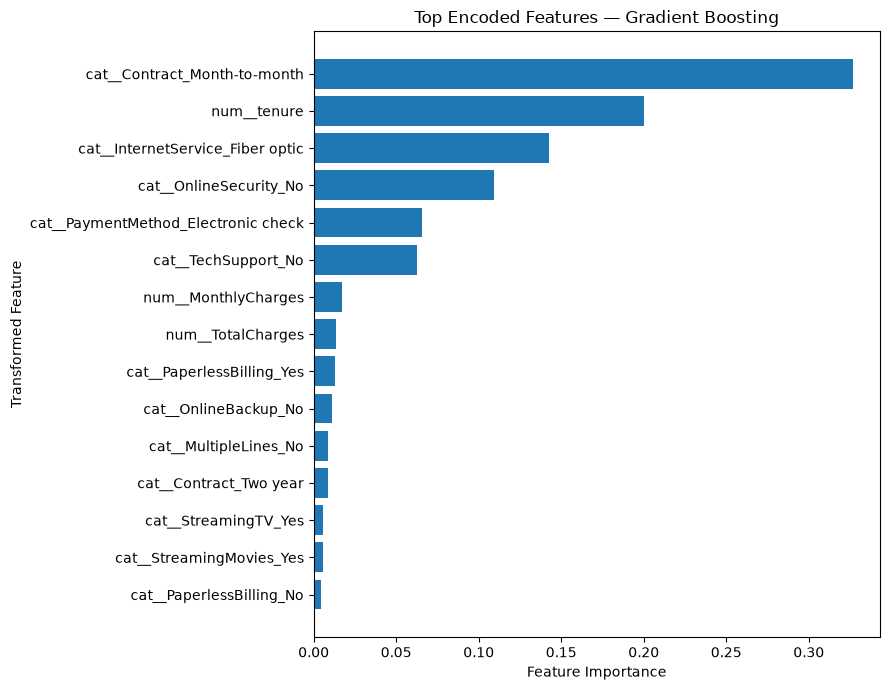

In [11]:
top_encoded_features = encoded_importance.head(15).sort_values(
    by="importance"
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_encoded_features["feature"],
    top_encoded_features["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Transformed Feature")
plt.title("Top Encoded Features — Gradient Boosting")

plt.tight_layout()
plt.show()

## Permutation Importance

Permutation importance evaluates how much predictive performance decreases when the values of a feature are randomly shuffled.

Unlike the model's internal feature importance, this analysis is performed directly on the original input variables.

A feature is considered important when disrupting its information produces a meaningful reduction in ROC-AUC.

Permutation importance is calculated on the held-out test data only for post-hoc interpretation. The results are not used for additional model selection or tuning.

In [12]:
permutation_results = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

In [13]:
permutation_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": permutation_results.importances_mean,
    "importance_std": permutation_results.importances_std
})

permutation_df = permutation_df.sort_values(
    by="importance_mean",
    ascending=False
).reset_index(drop=True)

permutation_df.round(4)

,feature,importance_mean,importance_std
0,tenure,0.0663,0.0046
1,Contract,0.0386,0.0041
2,InternetService,0.0146,0.0042
3,TotalCharges,0.0058,0.0013
4,MonthlyCharges,0.0046,0.0023
5,OnlineSecurity,0.0044,0.0014
6,MultipleLines,0.0031,0.0011
7,TechSupport,0.0029,0.0013
8,PaymentMethod,0.0029,0.0015
9,PaperlessBilling,0.0024,0.0010


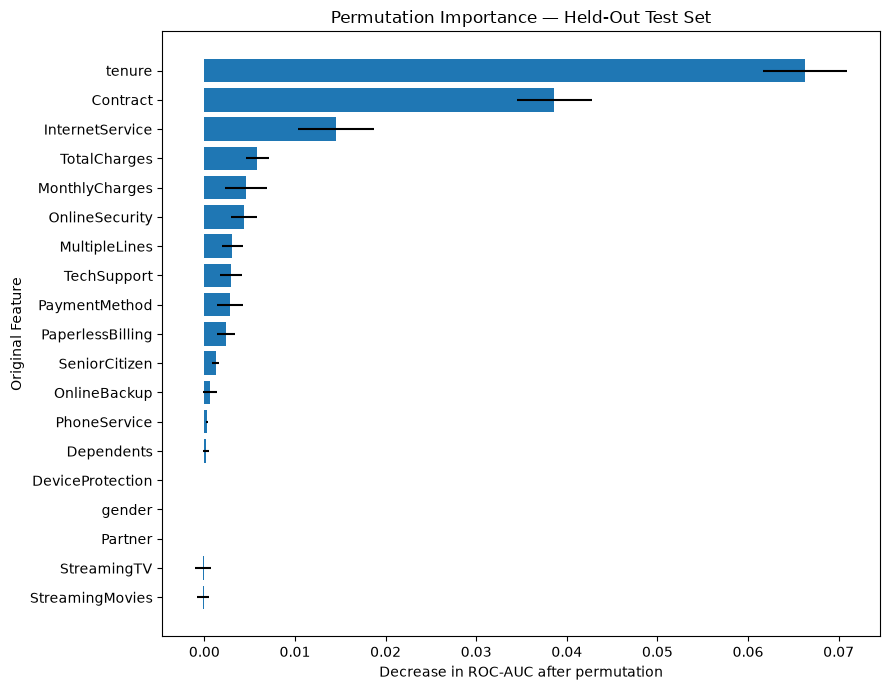

In [14]:
plot_permutation = permutation_df.sort_values(
    by="importance_mean"
)

plt.figure(figsize=(9, 7))

plt.barh(
    plot_permutation["feature"],
    plot_permutation["importance_mean"],
    xerr=plot_permutation["importance_std"]
)

plt.xlabel("Decrease in ROC-AUC after permutation")
plt.ylabel("Original Feature")
plt.title("Permutation Importance — Held-Out Test Set")

plt.tight_layout()
plt.show()

In [15]:
encoded_importance.head(15)

,feature,importance
0,cat__Contract_Month-to-month,0.326814
1,num__tenure,0.200355
2,cat__InternetService_Fiber optic,0.142661
3,cat__OnlineSecurity_No,0.108986
4,cat__PaymentMethod_Electronic check,0.065762
5,cat__TechSupport_No,0.062562
6,num__MonthlyCharges,0.016861
7,num__TotalCharges,0.013320
8,cat__PaperlessBilling_Yes,0.012981
9,cat__OnlineBackup_No,0.010886


In [16]:
permutation_df.round(4)

,feature,importance_mean,importance_std
0,tenure,0.0663,0.0046
1,Contract,0.0386,0.0041
2,InternetService,0.0146,0.0042
3,TotalCharges,0.0058,0.0013
4,MonthlyCharges,0.0046,0.0023
5,OnlineSecurity,0.0044,0.0014
6,MultipleLines,0.0031,0.0011
7,TechSupport,0.0029,0.0013
8,PaymentMethod,0.0029,0.0015
9,PaperlessBilling,0.0024,0.0010


In [17]:
def get_original_feature(transformed_feature):
    if transformed_feature.startswith("num__"):
        return transformed_feature.replace("num__", "", 1)

    if transformed_feature.startswith("cat__"):
        encoded_feature = transformed_feature.replace("cat__", "", 1)

        for original_feature in categorical_features:
            if (
                encoded_feature == original_feature
                or encoded_feature.startswith(
                    f"{original_feature}_"
                )
            ):
                return original_feature

    return transformed_feature


encoded_importance["original_feature"] = (
    encoded_importance["feature"]
    .apply(get_original_feature)
)

In [18]:
aggregated_importance = (
    encoded_importance
    .groupby(
        "original_feature",
        as_index=False
    )["importance"]
    .sum()
    .sort_values(
        by="importance",
        ascending=False
    )
    .reset_index(drop=True)
)

aggregated_importance.round(4)

,original_feature,importance
0,Contract,0.3357
1,tenure,0.2004
2,InternetService,0.1427
3,OnlineSecurity,0.1090
4,PaymentMethod,0.0658
5,TechSupport,0.0626
6,PaperlessBilling,0.0174
7,MonthlyCharges,0.0169
8,TotalCharges,0.0133
9,OnlineBackup,0.0109


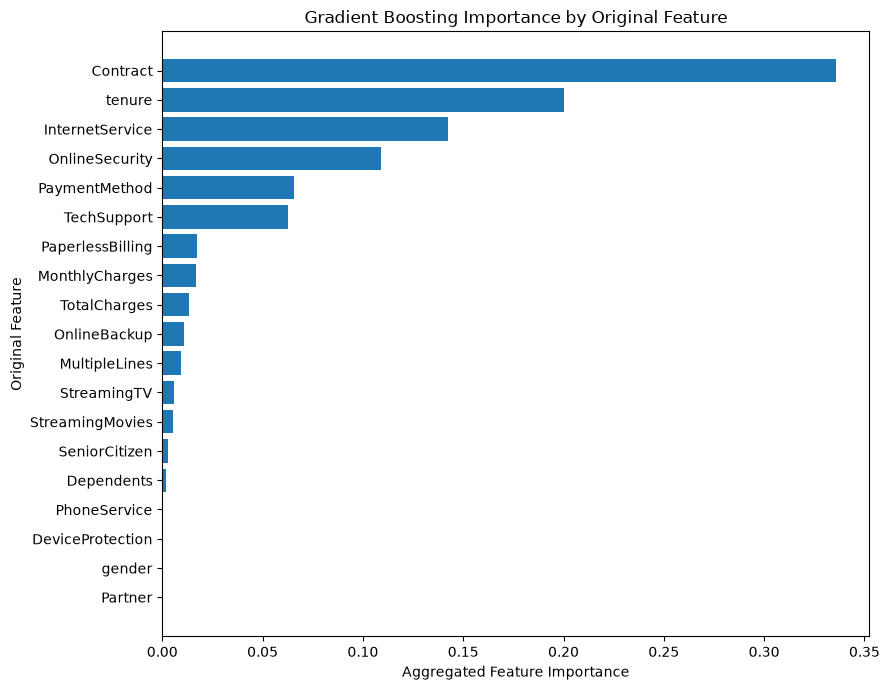

In [19]:
plot_aggregated = aggregated_importance.sort_values(
    by="importance"
)

plt.figure(figsize=(9, 7))

plt.barh(
    plot_aggregated["original_feature"],
    plot_aggregated["importance"]
)

plt.xlabel("Aggregated Feature Importance")
plt.ylabel("Original Feature")
plt.title(
    "Gradient Boosting Importance by Original Feature"
)

plt.tight_layout()
plt.show()

In [20]:
importance_comparison = (
    aggregated_importance
    .rename(
        columns={
            "importance": "model_importance"
        }
    )
    .merge(
        permutation_df[
            [
                "feature",
                "importance_mean",
                "importance_std"
            ]
        ],
        left_on="original_feature",
        right_on="feature",
        how="left"
    )
    .drop(columns="feature")
)

importance_comparison["model_rank"] = (
    importance_comparison["model_importance"]
    .rank(
        ascending=False,
        method="min"
    )
)

importance_comparison["permutation_rank"] = (
    importance_comparison["importance_mean"]
    .rank(
        ascending=False,
        method="min"
    )
)

importance_comparison = (
    importance_comparison
    .sort_values("permutation_rank")
    .reset_index(drop=True)
)

importance_comparison.round(4)

,original_feature,model_importance,importance_mean,importance_std,model_rank,permutation_rank
0,tenure,0.2004,0.0663,0.0046,2.0,1.0
1,Contract,0.3357,0.0386,0.0041,1.0,2.0
2,InternetService,0.1427,0.0146,0.0042,3.0,3.0
3,TotalCharges,0.0133,0.0058,0.0013,9.0,4.0
4,MonthlyCharges,0.0169,0.0046,0.0023,8.0,5.0
5,OnlineSecurity,0.1090,0.0044,0.0014,4.0,6.0
6,MultipleLines,0.0091,0.0031,0.0011,11.0,7.0
7,TechSupport,0.0626,0.0029,0.0013,6.0,8.0
8,PaymentMethod,0.0658,0.0029,0.0015,5.0,9.0
9,PaperlessBilling,0.0174,0.0024,0.0010,7.0,10.0


## Interpretation of Predictive Drivers

The interpretation methods consistently identify customer tenure, contract characteristics and internet service as major sources of predictive information.

The Gradient Boosting internal importance assigns particularly high importance to the month-to-month contract category, customer tenure and fiber-optic internet service. The absence of online security and technical support, as well as electronic-check payment, also contributes substantially to the model's tree structure.

Permutation importance provides a complementary view. `tenure` produces the largest reduction in ROC-AUC when its information is disrupted, followed by `Contract` and `InternetService`. This suggests that these variables contain especially important information for generalizing churn predictions to unseen customers.

The results are broadly consistent with the exploratory data analysis, where short tenure, month-to-month contracts, fiber-optic internet service, lack of online security or technical support and electronic-check payment were associated with higher churn rates.

The two importance methods should not be expected to produce identical rankings. Model-based feature importance measures how frequently and effectively variables are used in tree splits, while permutation importance measures the loss of predictive performance caused by disrupting a variable.

Correlated or redundant predictors may receive lower permutation importance because related variables can partially compensate when one feature is shuffled.

These findings represent predictive associations rather than causal effects. The analysis does not demonstrate that changing any individual feature would directly cause a change in customer churn.

In [21]:
aggregated_importance.round(4)

,original_feature,importance
0,Contract,0.3357
1,tenure,0.2004
2,InternetService,0.1427
3,OnlineSecurity,0.1090
4,PaymentMethod,0.0658
5,TechSupport,0.0626
6,PaperlessBilling,0.0174
7,MonthlyCharges,0.0169
8,TotalCharges,0.0133
9,OnlineBackup,0.0109


In [22]:
from sklearn.inspection import PartialDependenceDisplay

In [24]:
X_train_pdp = X_train.copy()

X_train_pdp[numeric_features] = (
    X_train_pdp[numeric_features]
    .astype(float)
)

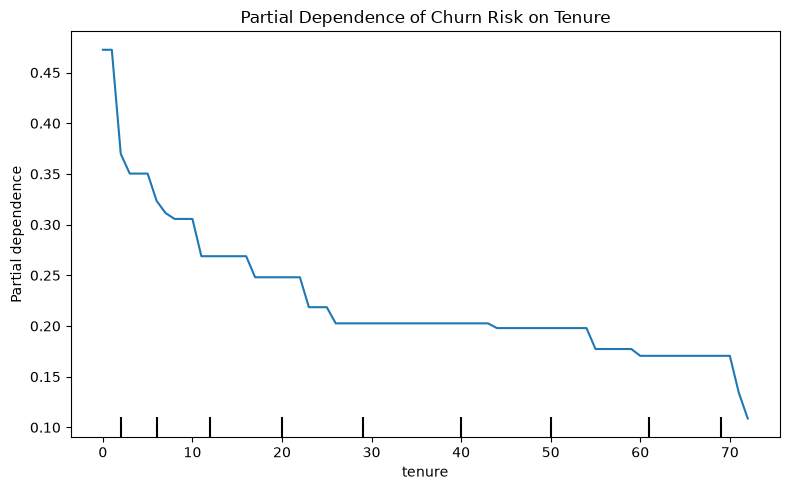

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))

PartialDependenceDisplay.from_estimator(
    final_model,
    X_train_pdp,
    features=["tenure"],
    kind="average",
    method="brute",
    ax=ax
)

ax.set_title(
    "Partial Dependence of Churn Risk on Tenure"
)

plt.tight_layout()
plt.show()

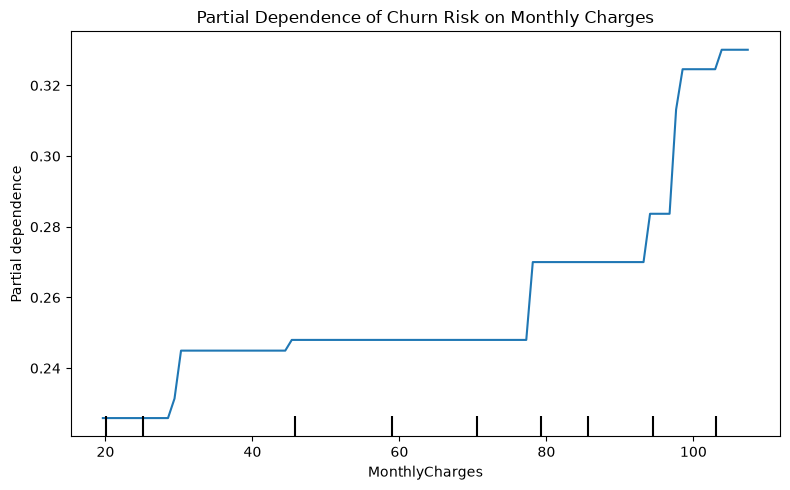

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))

PartialDependenceDisplay.from_estimator(
    final_model,
    X_train_pdp,
    features=["MonthlyCharges"],
    kind="average",
    method="brute",
    ax=ax
)

ax.set_title(
    "Partial Dependence of Churn Risk on Monthly Charges"
)

plt.tight_layout()
plt.show()

## Partial Dependence Interpretation

Partial dependence analysis provides additional information about the direction of the model's predictive relationships.

### Customer Tenure

The predicted churn risk decreases substantially as customer tenure increases.

Customers with very short tenure receive considerably higher average churn predictions, while customers who have remained with the company for several years show much lower predicted risk.

This pattern is consistent with both the exploratory analysis and the high permutation importance observed for `tenure`.

The result suggests that customer lifecycle stage is one of the strongest predictive signals in the model.

### Monthly Charges

Predicted churn risk generally increases as monthly charges rise.

The relationship is relatively stable across much of the middle range but becomes stronger at higher monthly charge levels.

This result is consistent with the exploratory analysis, where churned customers tended to have higher monthly charges on average.

### Interpretation Caveat

Partial dependence describes how the model's predictions change when a feature is varied while averaging over the remaining observations.

These relationships should not be interpreted causally. In particular, correlated variables such as tenure, contract type and total charges can make isolated feature effects difficult to interpret as real-world interventions.

The stepwise shape of the curves is also consistent with the final Gradient Boosting model being composed of shallow decision trees with a maximum depth of 1.